# **Import Library**

Tahap ini memuat semua library yang dibutuhkan untuk akses data, pengolahan raster, dan pembuatan dataset.

- Library utilitas: os, time, pathlib, contextlib, dotenv
- Library data dan visualisasi: numpy, pandas, matplotlib
- Library geospasial: rasterio, geopandas, shapely
- Library akses data: pystac_client, planetary_computer, h5py
- Library fitur dan model: skimage (GLCM), tensorflow (Dynamic World)

In [1]:
# Memuat seluruh pustaka pendukung analisis geospasial dan machine learning
import os
import h5py
import time
import shapely
import rasterio
import requests
import tempfile
import warnings
import numpy as np
import pandas as pd
import geopandas as gpd
import tensorflow as tf
from pathlib import Path
from contextlib import ExitStack
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import planetary_computer as pc
from pystac_client import Client
from urllib.parse import urlparse

from shapely.geometry import shape
from rasterio.enums import Resampling
from rasterio.warp import reproject, transform_bounds
from rasterio.warp import transform as warp_transform
from skimage.feature import graycomatrix, graycoprops
from rasterio.windows import Window, from_bounds, bounds as window_bounds
from rasterio.transform import from_bounds as transform_from_bounds, from_origin, rowcol

from pystac_client.stac_api_io import StacApiIO
from pystac_client.exceptions import APIError

warnings.filterwarnings("ignore")

# **Config**

Tahap ini menyiapkan kredensial, parameter global, koneksi katalog data, area studi (AOI), dan grid target.

- Membaca kredensial NASA dari `.env`
- Menetapkan resolusi 30 m, CRS `EPSG:32648`, rentang waktu 2025, direktori data, dan batas scene per sumber (maksimal 10, kecuali GEDI)
- Mengatur opsi GDAL agar pembacaan raster jarak jauh lebih hemat request
- Membuka klien STAC: NASA ORNL (GEDI L4A) dan Planetary Computer
- Memuat AOI dari `data/vector/bogor_administrasi_kabkota.shp` dan membuat grid 30 m

In [2]:
# Memuat variabel lingkungan dan kredensial akses
load_dotenv()
username_nasa = os.getenv("USERNAME_NASA")
password_nasa = os.getenv("PASSWORD_NASA")

In [3]:
# Menentukan parameter spasial, temporal, dan direktori penyimpanan
scale = 30
crs = "EPSG:32648"
datetime = "2024-03-25/2025-07-01"

MAX_SCENES = 10  # batas scene per sumber data (GEDI tidak dibatasi jumlahnya, hanya filter valid dan tanggal)

DATA_DIR = Path("data")
OUTPUT_DIR = DATA_DIR / "collections"
AOI_PATH = DATA_DIR / "vector" / "bogor_administrasi_kabkota.shp"

In [4]:
# Mengonfigurasi lingkungan GDAL dan menginisialisasi klien STAC API
rasterio_env = rasterio.Env(
    GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", VSI_CACHE=True,
    GDAL_HTTP_MAX_RETRY=3, GDAL_HTTP_RETRY_DELAY=2,
)
rasterio_env.__enter__()

STAC_IO = StacApiIO(timeout=(15, 60))

nasa_client = Client.open("https://cmr.earthdata.nasa.gov/stac/ORNL_CLOUD", stac_io=STAC_IO)
planetary_client = Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace, stac_io=STAC_IO)

In [5]:
# Memuat batas area studi (AOI) dan menyiapkan geometri pencarian
aoi_gdf = gpd.read_file(AOI_PATH).to_crs("EPSG:4326")
aoi = shapely.make_valid(
    aoi_gdf.geometry.union_all() if hasattr(aoi_gdf.geometry, "union_all") else aoi_gdf.geometry.unary_union
)
geometry = aoi.__geo_interface__
search_geometry = aoi.simplify(0.001).__geo_interface__  # versi ringan untuk query STAC (~100 m)
left, bottom, right, top = aoi.bounds

In [6]:
# Membuat grid raster target berdasarkan resolusi dan sistem koordinat
grid_l, grid_b, grid_r, grid_t = transform_bounds("EPSG:4326", crs, *aoi.bounds)
GRID_WIDTH = int(np.ceil((grid_r - grid_l) / scale))
GRID_HEIGHT = int(np.ceil((grid_t - grid_b) / scale))
GRID_TRANSFORM = from_origin(grid_l, grid_t, scale, scale)
GRID_SHAPE = (GRID_HEIGHT, GRID_WIDTH)
print(f"Grid {scale} m: {GRID_HEIGHT} x {GRID_WIDTH} piksel")

Grid 30 m: 1804 x 3054 piksel


# **SpatioTemporal Asset Catalog (STAC) API**

Tahap ini mendefinisikan fungsi pencarian dan pembacaan data dari katalog STAC untuk tiap sumber data.

- Fungsi pembantu untuk mengambil URL asset dan mencari item dengan retry
- **Sentinel-2:** scene L2A berawan < 10%, diurutkan berdasarkan tutupan awan
- **Sentinel-1:** scene RTC descending
- **GLO-30:** tile DEM yang memotong AOI
- **GEDI:** hanya L4A; login Earthdata, baca titik di AOI, lalu filter titik valid
- **Dynamic World:** muat model dan fungsi prediksi probabilitas 9 kelas

In [7]:
# Fungsi ekstraksi URL aset dan metadata item STAC
def extract_asset_urls(item, asset_keys):
    return {key: item.assets[key].href for key in asset_keys if key in item.assets}

def item_records(item, asset_keys, extra_properties=None):
    return {
        "id": item.id,
        "datetime": item.datetime.isoformat() if item.datetime else None,
        "urls": extract_asset_urls(item, asset_keys),
        "properties": {
            key: item.properties.get(key)
            for key in (extra_properties or [])
            if key in item.properties
        },
    }

In [8]:
# Fungsi pencarian item STAC dengan mekanisme percobaan ulang
def stac_items(client, limit=None, retries=2, **search_kwargs):
    for attempt in range(retries):
        try:
            return list(client.search(max_items=limit, **search_kwargs).items())
        except (requests.exceptions.RequestException, APIError, Exception):
            if attempt == retries - 1:
                raise
            time.sleep(2 ** attempt)

### **Sentinel-2**

In [9]:
# Fungsi pengumpulan metadata scene Sentinel-2 berawan rendah
def collect_sentinel2(bands, cloud_cover=10, max_scenes=MAX_SCENES):
    items = stac_items(
        planetary_client, limit=max_scenes,
        collections=["sentinel-2-l2a"], intersects=search_geometry, datetime=datetime,
        query={"eo:cloud_cover": {"lt": cloud_cover}},
        sortby=[{"field": "properties.eo:cloud_cover", "direction": "asc"}],
    )
    records = [item_records(item, bands, extra_properties=["eo:cloud_cover", "s2:mgrs_tile"]) for item in items]
    return sorted(records, key=lambda r: r["properties"].get("eo:cloud_cover", float("inf")))[:max_scenes]

### **Sentinel-1**

In [10]:
# Fungsi pengumpulan metadata scene radar Sentinel-1 RTC
def collect_sentinel1(polarizations=("vv", "vh"), orbit_direction="descending", max_scenes=MAX_SCENES):
    query = {"sat:orbit_state": {"eq": orbit_direction}} if orbit_direction else None
    items = stac_items(
        planetary_client, limit=max_scenes,
        collections=["sentinel-1-rtc"], intersects=search_geometry, datetime=datetime,
        query=query, sortby=[{"field": "properties.datetime", "direction": "asc"}],
    )
    return [item_records(item, polarizations, extra_properties=["sat:orbit_state"])
            for item in list(items)[:max_scenes]]

### **GLO-30**

In [11]:
# Fungsi pengumpulan metadata data elevasi Copernicus DEM GLO-30
def collect_glo30(asset_name="data", max_scenes=MAX_SCENES):
    glo_items = {
        "collections": ["cop-dem-glo-30"],
        "intersects": search_geometry,
    }
    glo_collection = tuple(stac_items(planetary_client, limit=max_scenes, **glo_items))
    asset_keys = [asset_name] if isinstance(asset_name, str) else asset_name
    return [item_records(item, asset_keys) for item in glo_collection]

### **Gedi**

In [12]:
# Sesi HTTP dengan penanganan pengalihan autentikasi NASA Earthdata
class SessionWithHeaderRedirection(requests.Session):
    AUTH_HOST = "urs.earthdata.nasa.gov"

    def __init__(self, username=None, password=None):
        super().__init__()
        if username and password:
            self.auth = (username, password)

    def rebuild_auth(self, prepared_request, response):
        if "Authorization" in prepared_request.headers:
            original_host = urlparse(response.request.url).hostname
            redirect_host = urlparse(prepared_request.url).hostname
            if original_host != redirect_host and self.AUTH_HOST not in (original_host, redirect_host):
                del prepared_request.headers["Authorization"]

In [13]:
# Validasi kredensial dan inisialisasi sesi NASA Earthdata
if not (username_nasa and password_nasa):
    raise ValueError("USERNAME_NASA dan PASSWORD_NASA belum terisi di file .env")

nasa_session = SessionWithHeaderRedirection(username_nasa, password_nasa)

In [14]:
# Konfigurasi parameter koleksi dan pembacaan data LiDAR GEDI L4A
gedi_l4a_collection = "GEDI_L4A_AGB_Density_V2_1_2056_2.1"

gedi_beams = [
    "BEAM0000", "BEAM0001", "BEAM0010", "BEAM0011",
    "BEAM0101", "BEAM0110", "BEAM1000", "BEAM1011",
]
gedi_l4a_keys = {
    "shot_number": "shot_number", "lon": "lon_lowestmode", "lat": "lat_lowestmode",
    "agbd": "agbd", "agbd_se": "agbd_se", "quality_flag": "l4_quality_flag",
}
AGBD_FILL = -9999.0

In [15]:
# Fungsi ekstraksi nama berkas dan pencarian granule GEDI
def gedi_filename(url):
    return os.path.basename(urlparse(url).path)

def collect_gedi(search_client, collection_id, asset_name="data"):
    # Tanpa batas jumlah: hanya dibatasi bbox AOI dan rentang `datetime`
    results = stac_items(
        search_client, limit=None,
        collections=[collection_id], bbox=list(aoi.bounds), datetime=datetime
    )
    _fallbacks = [asset_name, "HDF5", "HDF", "data", "granule"]
    scenes = []
    for item in results:
        try:  # lewati granule yang jelas tidak beririsan dengan batas administrasi (sebelum diunduh)
            if item.geometry and not shape(item.geometry).intersects(aoi):
                continue
        except Exception:
            pass
        url = next(
            (item.assets[k].href for k in _fallbacks if k in item.assets),
            next(
                (a.href for a in item.assets.values()
                 if getattr(a, "href", "").lower().endswith((".h5", ".hdf5"))),
                next((a.href for a in item.assets.values()), "")
            )
        )
        if url:
            scenes.append({"id": gedi_filename(url), "l4a": url})
    return sorted(scenes, key=lambda s: s["id"])

In [16]:
# Fungsi penyaringan titik GEDI berkualitas valid dan ekstraksi tanggal
def filter_valid_gedi(df):
    valid = (
        (df["quality_flag"] == 1)
        & np.isfinite(df["agbd"]) & (df["agbd"] > AGBD_FILL)
    )
    return df[valid].copy()

def gedi_acquisition_date(scene_id):
    return pd.to_datetime(scene_id.split("_")[2][:7], format="%Y%j").date()

In [17]:
# Fungsi pengunduhan dan pembacaan data granule HDF5 GEDI
def read_gedi_granule(session, asset_url, keys, bounds):
    left, bottom, right, top = bounds
    parts = {name: [] for name in keys}
    with tempfile.TemporaryDirectory() as tmp:
        h5_path = os.path.join(tmp, "gedi.h5")
        with session.get(asset_url, stream=True, timeout=120) as resp, open(h5_path, "wb") as f:
            resp.raise_for_status()
            for chunk in resp.iter_content(4 * 1024 * 1024): f.write(chunk)
        with h5py.File(h5_path, "r") as h5:
            for beam in filter(h5.__contains__, gedi_beams):
                lon, lat = h5[beam][keys["lon"]][:], h5[beam][keys["lat"]][:]
                mask = (lon >= left) & (lon <= right) & (lat >= bottom) & (lat <= top)
                if not mask.any():  # beam tidak melewati AOI: dataset lain tidak perlu dibaca
                    continue
                for name, ds in keys.items(): parts[name].append(h5[beam][ds][:][mask])
    return pd.DataFrame({k: np.concatenate(v) if v else np.array([]) for k, v in parts.items()})

def load_gedi_points(scene, bounds, area_geometry=None):
    try:
        pts = filter_valid_gedi(read_gedi_granule(nasa_session, scene["l4a"], gedi_l4a_keys, bounds))
        if area_geometry is not None and len(pts):
            area = shape(area_geometry)
            shapely.prepare(area)
            pts = pts[shapely.contains_xy(area, pts["lon"].to_numpy(), pts["lat"].to_numpy())]
        return pts
    except Exception as e:
        print(f"Peringatan: Gagal memuat data GEDI granule ({e})")
        return None

In [18]:
# Fungsi penggabungan tabel GEDI dan pemetaan titik ke piksel grid
def load_valid_gedi_table(csv_files):
    frames = [pd.read_csv(f) for f in csv_files]
    df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    if df.empty:
        raise ValueError("Tidak ada titik GEDI valid di AOI pada rentang waktu yang dipilih.")
    return df.drop_duplicates(subset="shot_number").reset_index(drop=True)

def locate_gedi_pixels(df):
    xs, ys = warp_transform("EPSG:4326", crs, df["lon"].tolist(), df["lat"].tolist())
    rows, cols = rowcol(GRID_TRANSFORM, xs, ys)
    located = df.assign(row=np.asarray(rows, dtype=int), col=np.asarray(cols, dtype=int))
    inside = located["row"].between(0, GRID_HEIGHT - 1) & located["col"].between(0, GRID_WIDTH - 1)
    return located[inside].reset_index(drop=True)

### **Dynamic Word**

In [19]:
# Konfigurasi model inferensi Dynamic World dan parameter normalisasi
dynamic_world_bands = ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B11", "B12"]
DW_CLASSES = ["water", "trees", "grass", "flooded_vegetation", "crops", "shrub_and_scrub", "built", "bare", "snow_and_ice"]
DW_INPUT_SHAPE = (512, 512)  # ukuran input model
DW_TILE = 170                # sisi tile inferensi (sel 30 m) = 5,1 km, ~10 m/piksel pada input model
dynamic_world_model_path = Path("models/dynamicword/forward")
dynamic_world_model = tf.saved_model.load(str(dynamic_world_model_path))

norm_percentiles = np.array([
    [1.7417268007636313, 2.023298706048351],
    [1.7261204997060209, 2.038905204308012],
    [1.6798346251414997, 2.179592821578937],
    [1.7734969472909623, 2.2890068333026603],
    [2.289154079164943, 2.6171674549378166],
    [2.382939712192371, 2.773418590375327],
    [2.3828939530384052, 2.7578332604178284],
    [2.1952484264967844, 2.789092484314204],
    [1.554812948247501, 2.4140534947492487],
], dtype="float32")

In [20]:
# Fungsi normalisasi citra dan inferensi probabilitas tutupan lahan
def normalize_dynamic_world(image):
    image = np.nan_to_num(image.astype("float32"), nan=0.0, posinf=0.0, neginf=0.0)
    image = np.log(image * 0.005 + 1.0)
    image = (image - norm_percentiles[:, 0]) / norm_percentiles[:, 1]
    image = np.exp(image * 5.0 - 1.0)
    return image / (image + 1.0)

def predict_dynamic_world(image):
    inputs = tf.convert_to_tensor(image[None, ...], dtype=tf.float32)
    logits = dynamic_world_model(inputs)
    return tf.nn.softmax(logits, axis=-1).numpy()[0]

# **Data collection**

Tahap ini mengunduh data AOI dari semua sumber dan menyimpannya sebagai checkpoint lokal di `data/collection`.

- Raster Sentinel-2, Sentinel-1, GLO-30 dibaca langsung pada resolusi ~30 m (memanfaatkan overview COG), sehingga request dan ukuran file jauh lebih kecil dibanding resolusi asli
- Dynamic World dijalankan per tile pada resolusi asli (~10 m) hanya di tile yang berisi titik GEDI valid, lalu diturunkan ke ~30 m
- Setiap file ditulis lewat file `.part` lalu di-rename, sehingga file checkpoint selalu utuh; file yang sudah ada dilewati saat download dilanjutkan
- Jumlah scene dibatasi `MAX_SCENES` per sumber; GEDI L4A tidak dibatasi jumlahnya, hanya oleh filter valid (quality_flag = 1, AGBD terisi) dan rentang `datetime`
- Titik GEDI valid per granule disimpan sebagai CSV di `data/collection/gedi_valid`

In [21]:
# Konfigurasi daftar dataset dan pemetaan band satelit
RASTER_DATASETS = ("sentinel02", "sentinel1", "glo30", "dynamic_world")
COLLECTION_BANDS = {
    "sentinel02": ["B02", "B03", "B04", "B05", "B06", "B07", "B08", "B11", "B12"],
    "sentinel1": ["vv", "vh"],
    "glo30": ["data"],
}

In [22]:
# Fungsi pembantu penamaan berkas dari tanggal dan ID scene
def collection_date(scene):
    value = scene.get("datetime") or scene.get("properties", {}).get("datetime")
    return pd.Timestamp(value).strftime("%Y%m%d") if value else "nodate"

def collection_scene_token(scene_id):
    token = "".join(c if c.isalnum() else "_" for c in str(scene_id))
    return token.strip("_")[:80] or "scene"

In [23]:
# Fungsi penentuan jendela spasial dan pembacaan raster
def aoi_footprint(source):
    l, b, r, t = transform_bounds("EPSG:4326", source.crs, left, bottom, right, top)
    l, b = max(l, source.bounds.left), max(b, source.bounds.bottom)
    r, t = min(r, source.bounds.right), min(t, source.bounds.top)
    if l >= r or b >= t:
        return None
    step_x, step_y = source.res if source.crs.is_geographic else (scale, scale)
    out_shape = (max(1, round((t - b) / step_y)), max(1, round((r - l) / step_x)))
    return (l, b, r, t), out_shape, transform_from_bounds(l, b, r, t, out_shape[1], out_shape[0])

def read_window(source, bounds, out_shape, resampling=Resampling.average):
    window = from_bounds(*bounds, transform=source.transform).round_offsets().round_lengths()
    window = window.intersection(Window(0, 0, source.width, source.height))
    return source.read(1, window=window, out_shape=out_shape, resampling=resampling, masked=True).astype("float32")

In [24]:
# Fungsi validasi GeoTIFF dan pengunduhan raster berbasis checkpoint
def is_valid_geotiff(path):
    if not path.exists() or path.stat().st_size < 10000:
        return False
    try:
        with rasterio.open(path) as src:
            src.read(1, window=Window(0, 0, min(1, src.width), min(1, src.height)))
            return True
    except Exception:
        return False

def write_dataset_scene_tif(dataset_name, scene, bands, output_dir=OUTPUT_DIR):
    valid_bands = [b for b in bands if b in scene.get("urls", {})]
    if not valid_bands:
        return None
    dataset_dir = Path(output_dir) / dataset_name
    dataset_dir.mkdir(parents=True, exist_ok=True)
    filename = f"{dataset_name}_{collection_date(scene)}_{collection_scene_token(scene['id'])}.tif"
    output_path = dataset_dir / filename
    if output_path.exists():
        if is_valid_geotiff(output_path):
            return output_path
        else:
            print(f"  [Warning] File korup terdeteksi: {filename}, mengunduh ulang...")
            output_path.unlink()

    with rasterio.open(scene["urls"][valid_bands[0]]) as ref_source:
        footprint = aoi_footprint(ref_source)
        if footprint is None:  # scene tidak beririsan dengan AOI
            return None
        bounds, out_shape, out_transform = footprint
        nodata = ref_source.nodata if ref_source.nodata is not None else -9999.0
        profile = dict(
            driver="GTiff", height=out_shape[0], width=out_shape[1], count=len(valid_bands),
            dtype="float32", crs=ref_source.crs, transform=out_transform, nodata=nodata,
            compress="deflate", predictor=3,
        )

    # Ambil image dan tulis band secara bertahap (file .part -> rename agar checkpoint selalu utuh)
    part_path = output_path.with_name(output_path.name + ".part")
    with rasterio.open(part_path, "w", **profile) as destination:
        for idx, band in enumerate(valid_bands, start=1):
            with rasterio.open(scene["urls"][band]) as source:
                destination.write(read_window(source, bounds, out_shape).filled(nodata), idx)
                destination.set_band_description(idx, band)
    os.replace(part_path, output_path)
    return output_path

def collect_raster_dataset(dataset_name, records, bands, max_scenes=MAX_SCENES):
    outputs = []
    for i, scene in enumerate(records[:max_scenes], start=1):
        print(f"  {dataset_name} {i}/{min(len(records), max_scenes)}: {scene['id']}")
        path = write_dataset_scene_tif(dataset_name, scene, bands)
        if path:
            outputs.append(path)
    return outputs

In [25]:
# Fungsi inferensi probabilitas Dynamic World per ubin spasial
def infer_dynamic_world_tile(sources, tile_bounds, tile_shape):
    image = np.stack([
        read_window(s, tile_bounds, DW_INPUT_SHAPE, Resampling.bilinear).filled(np.nan) for s in sources
    ], axis=-1)
    if not np.isfinite(image).any():
        return None
    probabilities = predict_dynamic_world(normalize_dynamic_world(image)).copy()
    probabilities[~np.isfinite(image).all(axis=-1)] = np.nan
    src_tf = transform_from_bounds(*tile_bounds, DW_INPUT_SHAPE[1], DW_INPUT_SHAPE[0])
    dst_tf = transform_from_bounds(*tile_bounds, tile_shape[1], tile_shape[0])
    out = np.full((len(DW_CLASSES), *tile_shape), np.nan, dtype="float32")
    for i in range(len(DW_CLASSES)):
        dst = np.full(tile_shape, np.nan, dtype="float32")
        reproject(
            source=np.ascontiguousarray(probabilities[..., i]), destination=dst,
            src_transform=src_tf, src_crs=sources[0].crs, dst_transform=dst_tf, dst_crs=sources[0].crs,
            src_nodata=np.nan, dst_nodata=np.nan, resampling=Resampling.average,
        )
        out[i] = dst
    return out

def dynamic_world_tiles(rows, cols, shape_hw, tile=DW_TILE):
    th, tw = min(tile, shape_hw[0]), min(tile, shape_hw[1])
    origins = {(min(r // tile * tile, shape_hw[0] - th), min(c // tile * tile, shape_hw[1] - tw))
               for r, c in zip(rows.tolist(), cols.tolist())}
    return sorted(origins), (th, tw)

In [26]:
# Fungsi penyimpanan hasil klasifikasi Dynamic World ke GeoTIFF
def write_dynamic_world_scene(scene, points, output_dir=OUTPUT_DIR):
    urls = scene.get("urls", {})
    if any(band not in urls for band in dynamic_world_bands):
        return None
    dataset_dir = Path(output_dir) / "dynamic_world"
    dataset_dir.mkdir(parents=True, exist_ok=True)
    output_path = dataset_dir / f"dynamic_world_{collection_date(scene)}_{collection_scene_token(scene['id'])}.tif"
    if output_path.exists() and output_path.stat().st_size > 0:
        return output_path

    with ExitStack() as stack:  # buka tiap band sekali per scene, bukan per tile
        sources = [stack.enter_context(rasterio.open(urls[band])) for band in dynamic_world_bands]
        footprint = aoi_footprint(sources[0])
        if footprint is None:
            return None
        _, (height, width), out_transform = footprint
        xs, ys = warp_transform("EPSG:4326", sources[0].crs, points["lon"].tolist(), points["lat"].tolist())
        rows, cols = (np.asarray(v, dtype=int) for v in rowcol(out_transform, xs, ys))
        inside = (rows >= 0) & (rows < height) & (cols >= 0) & (cols < width)
        tiles, (th, tw) = dynamic_world_tiles(rows[inside], cols[inside], (height, width))
        print(f"    {len(tiles)} tile berisi titik GEDI")
        result = np.full((len(DW_CLASSES), height, width), np.nan, dtype="float32")
        for r0, c0 in tiles:
            tile_bounds = window_bounds(Window(c0, r0, tw, th), out_transform)
            tile = infer_dynamic_world_tile(sources, tile_bounds, (th, tw))
            if tile is not None:
                result[:, r0:r0 + th, c0:c0 + tw] = tile
        profile = dict(
            driver="GTiff", height=height, width=width, count=len(DW_CLASSES), dtype="float32",
            crs=sources[0].crs, transform=out_transform, nodata=np.nan, compress="deflate", predictor=3,
        )

    part_path = output_path.with_name(output_path.name + ".part")
    with rasterio.open(part_path, "w", **profile) as destination:
        destination.write(result)
        for index, class_name in enumerate(DW_CLASSES, start=1):
            destination.set_band_description(index, class_name)
    os.replace(part_path, output_path)
    return output_path

def collect_dynamic_world_dataset(records, points, max_scenes=MAX_SCENES):
    outputs = []
    for i, scene in enumerate(records[:max_scenes], start=1):
        print(f"  dynamic_world {i}/{min(len(records), max_scenes)}: {scene['id']}")
        path = write_dynamic_world_scene(scene, points)
        if path:
            outputs.append(path)
    return outputs

In [27]:
# Fungsi penyimpanan titik observasi GEDI valid ke format CSV
def write_gedi_scene_table(scene, output_dir=OUTPUT_DIR):
    output_path = Path(output_dir) / "gedi_valid" / f"gedi_valid_{collection_scene_token(scene['id'])}.csv"
    if output_path.exists() and output_path.stat().st_size > 0:
        return output_path
    df_valid = load_gedi_points(scene, (left, bottom, right, top), area_geometry=geometry)
    if df_valid is None:
        return None
    df_valid = df_valid.assign(date=gedi_acquisition_date(scene["id"]))
    output_path.parent.mkdir(parents=True, exist_ok=True)
    part_path = output_path.with_name(output_path.name + ".part")
    df_valid.to_csv(part_path, index=False)
    os.replace(part_path, output_path)
    return output_path

def collect_gedi_valid_dataset(scenes):
    outputs = []
    for i, scene in enumerate(scenes, start=1):
        print(f"  gedi_valid {i}/{len(scenes)}: {scene['id']}")
        path = write_gedi_scene_table(scene)
        if path:
            outputs.append(path)
    return outputs

Eksekusi download per sumber. Setiap sel aman dijalankan ulang: file checkpoint yang sudah ada dilewati.

In [28]:
# Pengumpulan dan pengunduhan data raster Sentinel-2
written_files = {}

print("[1/5] Sentinel-2")
s2_records = collect_sentinel2(COLLECTION_BANDS["sentinel02"], cloud_cover=10)
written_files["sentinel02"] = collect_raster_dataset("sentinel02", s2_records, COLLECTION_BANDS["sentinel02"])
print("  tile MGRS:", sorted({r["properties"].get("s2:mgrs_tile") for r in s2_records}))

[1/5] Sentinel-2
  sentinel02 1/10: S2B_MSIL2A_20240722T025529_R032_T48MYU_20240722T082202
  sentinel02 2/10: S2A_MSIL2A_20240727T025531_R032_T48MYU_20240727T092050
  sentinel02 3/10: S2A_MSIL2A_20240826T025521_R032_T48MYU_20240826T085553
  sentinel02 4/10: S2A_MSIL2A_20240727T025531_R032_T48MXU_20240727T092050
  sentinel02 5/10: S2B_MSIL2A_20240722T025529_R032_T48MXT_20240722T082108
  sentinel02 6/10: S2B_MSIL2A_20240821T025529_R032_T48MYT_20240821T083420
  sentinel02 7/10: S2A_MSIL2A_20240617T025531_R032_T48MYU_20240617T091019
  sentinel02 8/10: S2A_MSIL2A_20240727T025531_R032_T48MYT_20240727T092050
  sentinel02 9/10: S2B_MSIL2A_20240722T025529_R032_T48MYT_20240722T082139
  sentinel02 10/10: S2B_MSIL2A_20240821T025529_R032_T48MXT_20240821T083420
  tile MGRS: ['48MXT', '48MXU', '48MYT', '48MYU']


In [29]:
# Pengumpulan dan pengunduhan data radar Sentinel-1
print("[2/5] Sentinel-1")
s1_records = collect_sentinel1(COLLECTION_BANDS["sentinel1"], orbit_direction="descending")
written_files["sentinel1"] = collect_raster_dataset("sentinel1", s1_records, COLLECTION_BANDS["sentinel1"])

[2/5] Sentinel-1
  sentinel1 1/10: S1A_IW_GRDH_1SDV_20240401T222557_20240401T222622_053246_067402_rtc
  sentinel1 2/10: S1A_IW_GRDH_1SDV_20240425T222557_20240425T222622_053596_0681CC_rtc
  sentinel1 3/10: S1A_IW_GRDH_1SDV_20240629T223411_20240629T223439_054544_06A368_rtc
  sentinel1 4/10: S1A_IW_GRDH_1SDV_20240706T222556_20240706T222621_054646_06A6FE_rtc
  sentinel1 5/10: S1A_IW_GRDH_1SDV_20240718T222555_20240718T222620_054821_06AD0C_rtc
  sentinel1 6/10: S1A_IW_GRDH_1SDV_20240730T222555_20240730T222620_054996_06B328_rtc
  sentinel1 7/10: S1A_IW_GRDH_1SDV_20240811T222555_20240811T222620_055171_06B954_rtc
  sentinel1 8/10: S1A_IW_GRDH_1SDV_20240823T222555_20240823T222620_055346_06BFCE_rtc
  sentinel1 9/10: S1A_IW_GRDH_1SDV_20240904T222555_20240904T222620_055521_06C650_rtc
  sentinel1 10/10: S1A_IW_GRDH_1SDV_20240916T222556_20240916T222621_055696_06CD3E_rtc


In [30]:
# Pengumpulan dan pengunduhan data elevasi DEM GLO-30
print("[3/5] GLO-30")
glo30_records = collect_glo30(asset_name=COLLECTION_BANDS["glo30"][0])
written_files["glo30"] = collect_raster_dataset("glo30", glo30_records, COLLECTION_BANDS["glo30"])

[3/5] GLO-30
  glo30 1/2: Copernicus_DSM_COG_10_S07_00_E107_00_DEM
  glo30 2/2: Copernicus_DSM_COG_10_S07_00_E106_00_DEM


In [31]:
# Pengumpulan dan penyaringan data LiDAR GEDI L4A
print("[4/5] GEDI L4A (titik valid)")
gedi_scenes = collect_gedi(nasa_client, gedi_l4a_collection)
print(f"  granule L4A pada AOI dan rentang waktu: {len(gedi_scenes)}")
written_files["gedi_valid"] = collect_gedi_valid_dataset(gedi_scenes)
if len(written_files["gedi_valid"]) < len(gedi_scenes):
    print(f"  PERINGATAN: {len(gedi_scenes) - len(written_files['gedi_valid'])} granule gagal; jalankan ulang sel ini untuk melanjutkan.")

[4/5] GEDI L4A (titik valid)
  granule L4A pada AOI dan rentang waktu: 32
  gedi_valid 1/32: GEDI04_A_2024132214314_O30661_04_T08521_02_004_01_V002.h5
  gedi_valid 2/32: GEDI04_A_2024134091658_O30684_01_T02240_02_004_01_V002.h5
  gedi_valid 3/32: GEDI04_A_2024143172555_O30829_04_T11367_02_004_01_V002.h5
  gedi_valid 4/32: GEDI04_A_2024192215707_O31592_04_T02829_02_004_02_V002.h5
  gedi_valid 5/32: GEDI04_A_2024196202115_O31653_04_T07404_02_004_02_V002.h5
  gedi_valid 6/32: GEDI04_A_2024198075646_O31676_01_T05086_02_004_02_V002.h5
  gedi_valid 7/32: GEDI04_A_2024223095229_O32065_04_T02829_02_004_02_V002.h5
  gedi_valid 8/32: GEDI04_A_2024227081558_O32126_04_T01865_02_004_02_V002.h5
  gedi_valid 9/32: GEDI04_A_2024277122706_O32904_04_T01406_02_004_01_V002.h5
  gedi_valid 10/32: GEDI04_A_2024281105216_O32965_04_T08674_02_004_01_V002.h5
  gedi_valid 11/32: GEDI04_A_2024282222811_O32988_01_T07779_02_004_01_V002.h5
  gedi_valid 12/32: GEDI04_A_2024285091729_O33026_04_T10403_02_004_01_V002.h5

In [32]:
# Memuat data titik GEDI valid dan memetakan lokasinya ke piksel grid
gedi_table = load_valid_gedi_table(written_files["gedi_valid"])
gedi_points = locate_gedi_pixels(gedi_table)
print(f"Titik GEDI valid: {len(gedi_points)} footprint | piksel unik: {len(gedi_points[['row', 'col']].drop_duplicates())}")

Titik GEDI valid: 19237 footprint | piksel unik: 19201


In [33]:
# Inferensi dan pembuatan data tutupan lahan Dynamic World
print("[5/5] Dynamic World")
written_files["dynamic_world"] = collect_dynamic_world_dataset(s2_records, gedi_points)

[5/5] Dynamic World
  dynamic_world 1/10: S2B_MSIL2A_20240722T025529_R032_T48MYU_20240722T082202
  dynamic_world 2/10: S2A_MSIL2A_20240727T025531_R032_T48MYU_20240727T092050
  dynamic_world 3/10: S2A_MSIL2A_20240826T025521_R032_T48MYU_20240826T085553
  dynamic_world 4/10: S2A_MSIL2A_20240727T025531_R032_T48MXU_20240727T092050
  dynamic_world 5/10: S2B_MSIL2A_20240722T025529_R032_T48MXT_20240722T082108
  dynamic_world 6/10: S2B_MSIL2A_20240821T025529_R032_T48MYT_20240821T083420
  dynamic_world 7/10: S2A_MSIL2A_20240617T025531_R032_T48MYU_20240617T091019
  dynamic_world 8/10: S2A_MSIL2A_20240727T025531_R032_T48MYT_20240727T092050
  dynamic_world 9/10: S2B_MSIL2A_20240722T025529_R032_T48MYT_20240722T082139
  dynamic_world 10/10: S2B_MSIL2A_20240821T025529_R032_T48MXT_20240821T083420


In [34]:
# Menampilkan ringkasan berkas data yang berhasil dikumpulkan
print("\n ====== Summary of Collected Files ======")
for dataset, paths in written_files.items():
    print(f"{dataset}: {len(paths)} file")


 ====== Summary of Collected Files ======
sentinel02: 10 file
sentinel1: 10 file
glo30: 2 file
gedi_valid: 32 file
dynamic_world: 10 file


# **Data Preprocessing (Feature Engineering)**

Tahap ini menyeragamkan semua dataset ke satu grid 30 m, membuat komposit temporal median, dan mengekstrak fitur input model.

- Mereproyeksi semua raster ke grid target
- **Komposit temporal median** per band/kelas dari seluruh scene, dihitung sebelum dicocokkan dengan lokasi GEDI (satu band per iterasi agar hemat memori)
- **Sentinel-2:** band reflektansi dan indeks vegetasi (DVI, EVI, GNDVI, NDVI, RVI)
- **Sentinel-1:** VV dan VH dalam dB, serta tekstur GLCM (hanya dihitung pada piksel GEDI valid)
- **GLO-30:** elevasi, slope, dan aspect
- **Dynamic World:** median probabilitas tiap kelas
- Menggabungkan semua fitur ke `all_features`

In [35]:
# Fungsi reproyeksi raster ke grid target dan operasi pembagian aman
def reproject_to_grid(src_path, band_index=1, resampling=Resampling.bilinear):
    with rasterio.open(src_path) as src:
        dst = np.full(GRID_SHAPE, np.nan, dtype="float32")
        reproject(
            source=rasterio.band(src, band_index), destination=dst,
            src_transform=src.transform, src_crs=src.crs, src_nodata=src.nodata,
            dst_transform=GRID_TRANSFORM, dst_crs=crs, dst_nodata=np.nan,
            resampling=resampling,
        )
        return dst

def safe_divide(num, den):
    return np.divide(num, den, out=np.full_like(num, np.nan, dtype="float32"), where=np.abs(den) > 1e-6)

In [36]:
# Fungsi pembuatan komposit median temporal dari tumpukan raster
def temporal_median(files, band_index=1):
    valid_layers = []
    for f in files:
        try:
            valid_layers.append(reproject_to_grid(f, band_index))
        except Exception as e:
            print(f"  [Warning] Gagal membaca {Path(f).name} band {band_index}: {e}")
    if not valid_layers:
        return np.full(GRID_SHAPE, np.nan, dtype="float32")
    stack = np.stack(valid_layers)
    return np.nanmedian(stack, axis=0).astype("float32")

### **Sentinel-2**

In [37]:
# Fungsi ekstraksi band spektral dan indeks vegetasi Sentinel-2
def preprocess_sentinel2_features(s2_files):
    bands = COLLECTION_BANDS["sentinel02"]
    comp = {b: temporal_median(s2_files, i) for i, b in enumerate(bands, 1)}

    scale_refl = lambda x: x * 0.0001 if np.nanmedian(x) > 10 else x
    b2, b3, b4, b8 = scale_refl(comp["B02"]), scale_refl(comp["B03"]), scale_refl(comp["B04"]), scale_refl(comp["B08"])

    scale_dn = lambda x: x * 10000.0 if np.nanmedian(x) < 10 else x
    b5, b6, b11, b12 = scale_dn(comp["B05"]), scale_dn(comp["B06"]), scale_dn(comp["B11"]), scale_dn(comp["B12"])

    return {
        "B2": b2, "B3": b3, "B4": b4, "B8": b8,
        "B5": b5, "B6": b6, "B11": b11, "B12": b12,
        "DVI": b8 - b4,
        "EVI": 2.5 * safe_divide(b8 - b4, b8 + 6.0 * b4 - 7.5 * b2 + 1.0),
        "GNDVI": safe_divide(b8 - b3, b8 + b3),
        "NDVI": safe_divide(b8 - b4, b8 + b4),
        "RVI": safe_divide(b8, b4),
    }

In [38]:
# Ekstraksi fitur spektral Sentinel-2
features_s2 = preprocess_sentinel2_features(written_files["sentinel02"])

### **Sentinel-1**

In [39]:
# Fungsi kuantisasi citra dan ekstraksi fitur tekstur GLCM
def quantize_texture(img, low=-25, high=0):
    scaled = (np.nan_to_num(img, nan=low) - low) / max(high - low, 1e-6)
    return np.clip(scaled * 63, 0, 63).astype("uint8")

def glcm_features(img, rows, cols, window=5):
    rad = window // 2
    padded = np.pad(quantize_texture(img), rad, mode="edge")
    res = {k: np.full(img.shape, np.nan, dtype="float32") for k in ("contrast", "corr", "ent")}
    dist, angles = [1], [0, np.pi/4, np.pi/2, 3*np.pi/4]
    for r, c in set(zip(rows.tolist(), cols.tolist())):
        m = graycomatrix(padded[r:r+window, c:c+window], dist, angles, levels=64, symmetric=True, normed=True)
        p = m.astype("float32")
        res["contrast"][r, c] = np.nanmean(graycoprops(m, "contrast"))
        res["corr"][r, c] = np.nanmean(graycoprops(m, "correlation"))
        res["ent"][r, c] = np.nanmean(-(p * np.log2(np.maximum(p, 1e-12))).sum(axis=(0, 1, 2)))
    return res

In [40]:
# Fungsi prapemrosesan data polarisasi dan tekstur Sentinel-1
def preprocess_sentinel1_features(s1_files, rows, cols):
    vv, vh = temporal_median(s1_files, 1), temporal_median(s1_files, 2)
    vv_db = (10.0 * np.log10(np.maximum(vv, 1e-5)) if np.nanmedian(vv) > 0 else vv).astype("float32")
    vh_db = (10.0 * np.log10(np.maximum(vh, 1e-5)) if np.nanmedian(vh) > 0 else vh).astype("float32")
    vv_tex, vh_tex = glcm_features(vv_db, rows, cols), glcm_features(vh_db, rows, cols)
    return {
        "VV": vv_db, "VV_contrast": vv_tex["contrast"], "VV_corr": vv_tex["corr"], "VV_ent": vv_tex["ent"],
        "VH": vh_db, "VH_contrast": vh_tex["contrast"], "VH_corr": vh_tex["corr"], "VH_ent": vh_tex["ent"],
    }

In [41]:
# Ekstraksi fitur hamburan balik dan tekstur Sentinel-1
features_s1 = preprocess_sentinel1_features(
    written_files["sentinel1"], gedi_points["row"].to_numpy(), gedi_points["col"].to_numpy()
)

### **GLO-30**

In [42]:
# Fungsi ekstraksi parameter topografi elevasi, kelerengan, dan aspek
def preprocess_dem_features(dem_files):
    dem = temporal_median(dem_files, 1)  # tile yang tidak saling tumpang tindih -> median = mosaik
    gy, gx = np.gradient(dem, scale)
    slope = np.degrees(np.arctan(np.hypot(gx, gy))).astype("float32")
    aspect = np.mod(np.degrees(np.arctan2(-gx, gy)), 360.0).astype("float32")
    return {"dem": dem, "slope": slope, "aspect": aspect}

In [43]:
# Ekstraksi fitur topografi dari DEM GLO-30
features_dem = preprocess_dem_features(written_files["glo30"])

### **Dynamic Word**

In [44]:
# Fungsi ekstraksi probabilitas kelas Dynamic World
def preprocess_dynamic_world_features(dw_files):
    return {c: temporal_median(dw_files, i) for i, c in enumerate(DW_CLASSES, 1)}

In [45]:
# Ekstraksi fitur probabilitas kelas Dynamic World
features_dw = preprocess_dynamic_world_features(written_files["dynamic_world"])

### **Concatenated Features**

In [46]:
# Penggabungan seluruh fitur prediktor ke dalam satu dictionary
all_features = {**features_s2, **features_s1, **features_dem, **features_dw}
pd.DataFrame({
    "Dataset": ["Sentinel-2", "Sentinel-1", "GLO-30", "Dynamic Word"],
    "Jumlah": [len(features_s2), len(features_s1), len(features_dem), len(features_dw)]
})

,Dataset,Jumlah
0,Sentinel-2,13
1,Sentinel-1,8
2,GLO-30,3
3,Dynamic Word,9


# **Build Dataset**

Tahap ini mengambil nilai fitur komposit pada piksel yang memiliki titik GEDI valid, menyusunnya menjadi tabel, menampilkan petanya, dan mengekspornya ke CSV.

- Mengambil nilai setiap fitur pada indeks (row, col) tiap footprint GEDI valid
- Menambahkan `shot_number`, `date`, `latitude`, `longitude`, dan target GEDI L4A (`agbd`, `agbd_se`)
- Membuang baris yang memiliki fitur NaN dan melaporkan fitur penyebabnya
- Menampilkan peta titik data beserta batas administrasi Bogor
- Mengekspor tabel ke `data/collection`, lalu menghapus semua tif checkpoint

In [47]:
# Fungsi pengambilan sampel fitur pada titik GEDI dan pembentukan dataset
def sample_features(features, rows, cols):
    return pd.DataFrame({name: array[rows, cols] for name, array in features.items()})

def build_dataset(points, features):
    X = sample_features(features, points["row"].to_numpy(), points["col"].to_numpy())
    table = pd.concat([
        points[["shot_number", "date"]],
        points[["lat", "lon"]].rename(columns={"lat": "latitude", "lon": "longitude"}),
        X,
        points[["agbd", "agbd_se"]],
    ], axis=1)
    keep = np.isfinite(X.to_numpy()).all(axis=1)
    nan_counts = X.isna().sum()
    print(f"Footprint valid: {len(table)} | fitur lengkap: {keep.sum()} | dibuang (fitur NaN): {(~keep).sum()}")
    if (~keep).any():
        print("NaN per fitur:", nan_counts[nan_counts > 0].to_dict())
    return table[keep].reset_index(drop=True)

In [ ]:
# Fungsi visualisasi sebaran spasial titik observasi GEDI
def plot_dataset_map(table, boundary, value="agbd"):
    fig, ax = plt.subplots(figsize=(12, 10))
    boundary.boundary.plot(ax=ax, color="black", linewidth=0.8)
    sc = ax.scatter(
        table["longitude"], table["latitude"], c=table[value], cmap="YlGn", s=6,
        vmin=0, vmax=np.nanpercentile(table[value], 98),
    )
    fig.colorbar(sc, ax=ax, shrink=0.55, label="AGBD (Mg/ha)")
    ax.set_title(f"Titik GEDI L4A valid ({len(table)} footprint)", fontweight="bold")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_aspect("equal")
    ax.grid(ls="--", alpha=0.4)
    plt.show()

In [49]:
# Fungsi ekspor dataset tabular ke CSV dan pembersihan berkas perantara
def export_dataset(table, output_dir=OUTPUT_DIR, filename="dataset_gedi_valid.csv"):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    output_path = output_dir / filename
    table.to_csv(output_path, index=False)
    return output_path

def cleanup_checkpoints(base_dir=OUTPUT_DIR, datasets=RASTER_DATASETS):
    removed = 0
    for ds in datasets:
        ds_dir = Path(base_dir) / ds
        if not ds_dir.is_dir():
            continue
        for f in ds_dir.glob("*.tif*"):  # *.tif dan sisa *.tif.part
            f.unlink()
            removed += 1
        if not any(ds_dir.iterdir()):
            ds_dir.rmdir()
    return removed

In [ ]:
# Membangun dataset tabular dari titik GEDI dan seluruh fitur raster
dataset = build_dataset(gedi_points, all_features)
dataset.head()

Footprint valid: 19237 | fitur lengkap: 19237 | dibuang (fitur NaN): 0


,shot_number,date,latitude,longitude,B2,B3,B4,B8,B5,B6,...,trees,grass,flooded_vegetation,crops,shrub_and_scrub,built,bare,snow_and_ice,agbd,agbd_se
0,306610000400333411,2024-05-11,-6.603688,106.427483,0.155018,0.170275,0.147798,0.416123,1984.336182,3625.153809,...,0.084233,0.161481,0.092946,0.347132,0.080208,0.051876,0.080124,0.068288,46.47198,17.129469
1,306610000400333412,2024-05-11,-6.604117,106.427789,0.147658,0.165313,0.144363,0.395872,1967.736328,3545.214355,...,0.075957,0.163879,0.086300,0.379986,0.080350,0.049339,0.077204,0.053833,80.13713,17.123276
2,306610000400333414,2024-05-11,-6.604985,106.428406,0.144522,0.160895,0.139014,0.397165,1980.809326,3538.424805,...,0.080502,0.119384,0.094174,0.450283,0.064786,0.052953,0.063396,0.042924,43.05177,17.128086
3,306610000400333415,2024-05-11,-6.605417,106.428714,0.149759,0.177135,0.147203,0.436247,2177.345703,3819.861084,...,0.073846,0.140897,0.112006,0.395894,0.064323,0.050501,0.085489,0.047077,65.6055,17.126152
4,306610000400333419,2024-05-11,-6.607084,106.429907,0.154845,0.165083,0.140470,0.424475,1943.416748,3634.666260,...,0.077789,0.173967,0.097174,0.373097,0.062082,0.060657,0.069853,0.053730,100.05565,17.123373


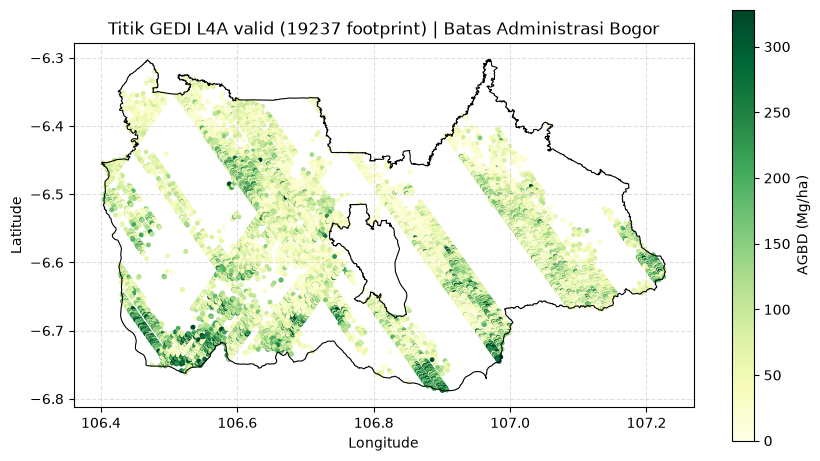

In [51]:
# Visualisasi peta sebaran titik sampel dataset
plot_dataset_map(dataset, aoi_gdf)

In [52]:
# Menyimpan dataset akhir ke berkas CSV dan membersihkan checkpoint
csv_path = export_dataset(dataset)
print(f"Dataset berhasil disimpan: {csv_path} | {dataset.shape[0]} baris x {dataset.shape[1]} kolom")

if len(dataset) > 0 and csv_path.stat().st_size > 0:
    print(f"File tif checkpoint dihapus: {cleanup_checkpoints()}")
else:
    print("Tabel kosong: tif checkpoint dipertahankan untuk pemeriksaan.")

Dataset berhasil disimpan: data\collections\dataset_gedi_valid.csv | 19237 baris x 39 kolom
File tif checkpoint dihapus: 32
